# TP4 — Régression : estimer le prix des logements en Californie (Correction)

Cours associé : [TP4_Cours.md](TP4_Cours.md) · Pense-bête : [Pense_bete_Pandas.md](../Pense_bete_Pandas.md)

## Contexte

Une agence immobilière souhaite un outil d'estimation rapide du prix des logements. Vous disposez des données du recensement californien de 1990, agrégées par **quartier** (*block group*, quelques centaines à quelques milliers d'habitants). Pour 20 640 quartiers :

| Colonne | Signification |
|---|---|
| `MedInc` | revenu médian des ménages (en dizaines de milliers de $) |
| `HouseAge` | âge médian des logements (années) |
| `AveRooms`, `AveBedrms` | nombre moyen de pièces et de chambres par logement |
| `Population` | nombre d'habitants du quartier |
| `AveOccup` | nombre moyen d'occupants par logement |
| `Latitude`, `Longitude` | position du quartier |
| `MedHouseVal` | **cible** : valeur médiane des logements (en centaines de milliers de $) |

## Déroulé

| Partie | Contenu |
|---|---|
| 1 | Exploration des données |
| 2 | Baseline et régression linéaire simple |
| 3 | Régression linéaire multiple et analyse des résidus |
| 4 | Variables polynomiales et régularisation |
| 5 | Modèles à base d'arbres |
| 6 | Comparaison finale et analyse des erreurs |
| 7 | *Facultatif* : approfondissements |

Les cellules marquées `# TODO` sont à compléter. Les cellules ✍️ attendent une réponse rédigée.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from xgboost import XGBRegressor

plt.rcParams["figure.figsize"] = (8, 5)
RANDOM_STATE = 42

## Partie 1 — Exploration des données

**1.1** Chargez `data/california_housing.csv` dans `df`. Affichez les dimensions, les valeurs manquantes et les statistiques descriptives. Repérez-vous des valeurs surprenantes ?

In [2]:
# TODO : chargement et statistiques descriptives
df = pd.read_csv("data/california_housing.csv")
print(df.shape)
print(df.isna().sum().sum(), "valeurs manquantes")
df.describe().round(2)

(20640, 9)
0 valeurs manquantes


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


**1.2** Tracez l'histogramme de la cible `MedHouseVal` (100 classes). Combien de quartiers ont exactement la valeur maximale ? Qu'en déduisez-vous ?

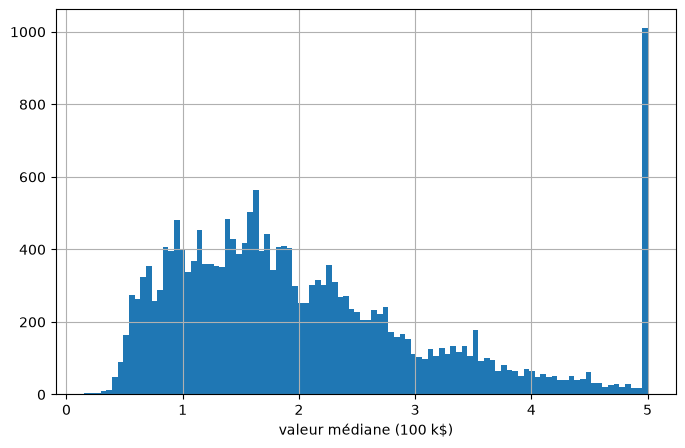

valeur max : 5.00001
quartiers à la valeur max : 965


In [3]:
# TODO : distribution de la cible
df["MedHouseVal"].hist(bins=100)
plt.xlabel("valeur médiane (100 k$)")
plt.show()
print("valeur max :", df["MedHouseVal"].max())
print("quartiers à la valeur max :", (df["MedHouseVal"] == df["MedHouseVal"].max()).sum())

**1.3** Représentez les quartiers sur une carte : nuage de points `Longitude` / `Latitude`, colorés par `MedHouseVal` (`cmap="viridis"`, petits points semi-transparents). Où sont les logements les plus chers ?

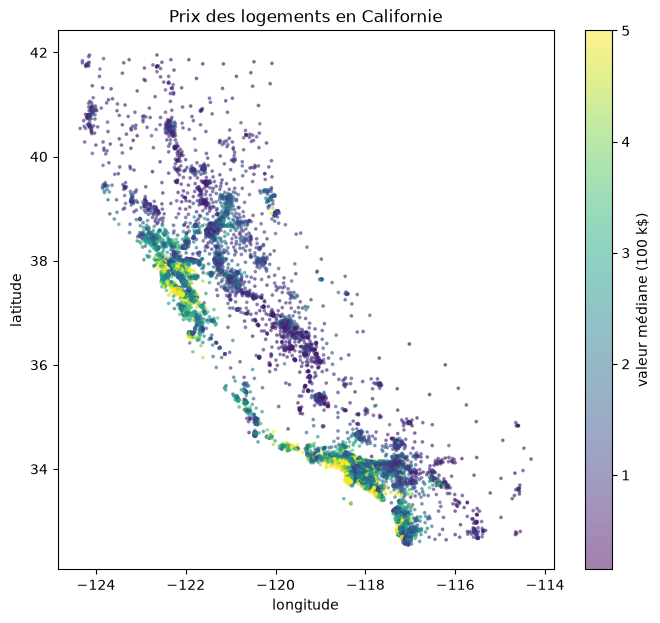

In [4]:
# TODO : carte des prix
plt.figure(figsize=(8, 7))
plt.scatter(df["Longitude"], df["Latitude"], c=df["MedHouseVal"], cmap="viridis", s=3, alpha=0.5)
plt.colorbar(label="valeur médiane (100 k$)")
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.title("Prix des logements en Californie")
plt.show()

**1.4** Calculez les corrélations de chaque variable avec la cible, triées. Tracez le nuage `MedInc` / `MedHouseVal`.

MedHouseVal    1.000
MedInc         0.688
AveRooms       0.152
HouseAge       0.106
AveOccup      -0.024
Population    -0.025
Longitude     -0.046
AveBedrms     -0.047
Latitude      -0.144
Name: MedHouseVal, dtype: float64


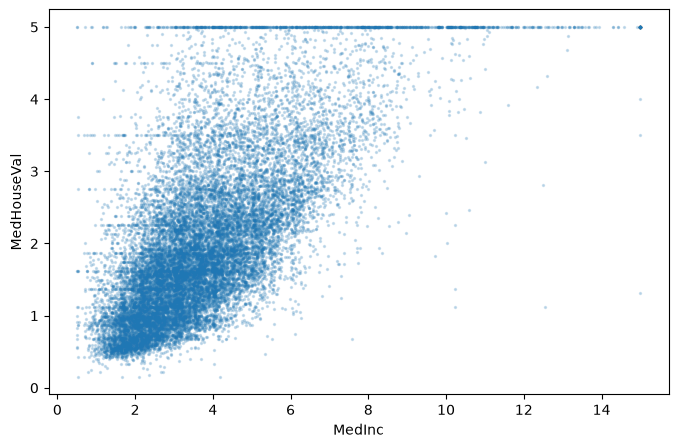

In [5]:
# TODO : corrélations et nuage revenu / prix
print(df.corr()["MedHouseVal"].sort_values(ascending=False).round(3))
df.plot.scatter(x="MedInc", y="MedHouseVal", s=2, alpha=0.2)
plt.show()

✅ **Éléments de réponse**

- Aucune valeur manquante, mais des valeurs extrêmes : `AveRooms` monte à plus de 140 pièces, `AveOccup` à plus de 1 200 occupants par logement (quartiers très atypiques : résidences, hôtels, erreurs de recensement). `Population` va jusqu'à 35 000.
- La cible est **plafonnée** à 5,00001 (500 000 $) : 965 quartiers ont exactement cette valeur. Le vrai prix y est supérieur, mais inconnu : la cible est **censurée**. Aucun modèle ne pourra bien prédire ces quartiers.
- Les prix les plus élevés se concentrent **sur la côte**, autour de la baie de San Francisco et de Los Angeles / San Diego ; l'intérieur des terres est bien moins cher. La localisation est cruciale, mais pas linéaire (ni la latitude ni la longitude seules ne l'expriment).
- Le **revenu médian** est de loin la variable la plus corrélée au prix (≈ 0,69). Les autres corrélations linéaires sont faibles. Sur le nuage, on voit aussi la ligne horizontale du plafond à 5.

## Partie 2 — Baseline et régression linéaire simple

**2.1** Séparez `X` (toutes les colonnes sauf la cible) et `y`, puis découpez en 80 % / 20 % avec `random_state=RANDOM_STATE`.

In [6]:
# TODO : découpage
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

(16512, 8) (4128, 8)


La fonction suivante calcule les métriques sur le jeu de test et mémorise les résultats. Elle convertit MAE et RMSE en **milliers de dollars** pour qu'ils soient parlants.

In [7]:
resultats = {}

def evaluer(nom, modele, X_eval=None, y_eval=None):
    X_eval = X_test if X_eval is None else X_eval
    y_eval = y_test if y_eval is None else y_eval
    y_pred = modele.predict(X_eval)
    resultats[nom] = {
        "MAE (k$)": mean_absolute_error(y_eval, y_pred) * 100,
        "RMSE (k$)": root_mean_squared_error(y_eval, y_pred) * 100,
        "R²": r2_score(y_eval, y_pred),
    }
    return pd.DataFrame(resultats).T.round(3)

**2.2** Évaluez un `DummyRegressor()` (prédit toujours la moyenne), puis une `LinearRegression` n'utilisant **que** `MedInc`. Tracez la droite obtenue par-dessus le nuage de points du jeu de test. Interprétez la pente.

prix ≈ 0.445 + 0.419 × MedInc


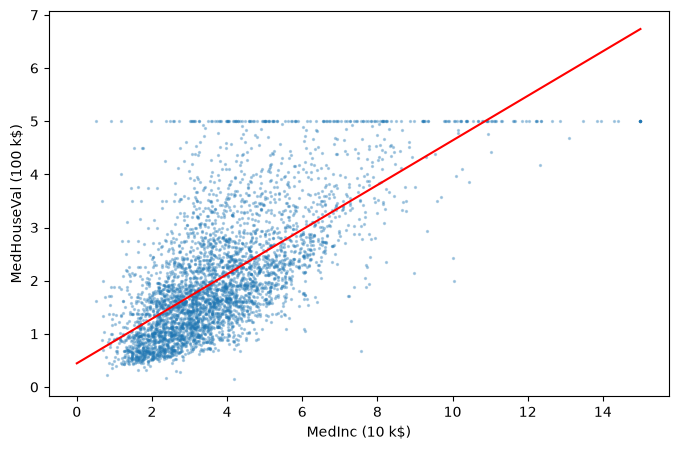

,MAE (k$),RMSE (k$),R²
moyenne,90.607,114.486,-0.000
linéaire (MedInc seul),62.991,84.209,0.459


In [8]:
# TODO : baseline et régression simple
evaluer("moyenne", DummyRegressor().fit(X_train, y_train))

lin_simple = LinearRegression().fit(X_train[["MedInc"]], y_train)
print(f"prix ≈ {lin_simple.intercept_:.3f} + {lin_simple.coef_[0]:.3f} × MedInc")

plt.scatter(X_test["MedInc"], y_test, s=2, alpha=0.3)
grille = pd.DataFrame({"MedInc": np.linspace(0, 15, 100)})
plt.plot(grille["MedInc"], lin_simple.predict(grille), color="red")
plt.xlabel("MedInc (10 k$)")
plt.ylabel("MedHouseVal (100 k$)")
plt.show()
evaluer("linéaire (MedInc seul)", lin_simple, X_test[["MedInc"]])

✅ **Éléments de réponse**

- La baseline (prédire la moyenne) se trompe en moyenne d'environ 90 k$, avec un R² de 0 par construction.
- Avec le seul revenu, la pente vaut environ 0,42 : **10 000 $ de revenu médian en plus correspondent en moyenne à 42 000 $ de valeur immobilière en plus**. Ce modèle explique déjà près de la moitié de la variance (R² ≈ 0,46) et fait baisser la MAE à 63 k$.

## Partie 3 — Régression linéaire multiple et analyse des résidus

**3.1** Créez un pipeline `lin` (`StandardScaler` + `LinearRegression`) utilisant toutes les variables, entraînez-le et évaluez-le.

In [9]:
# TODO : régression linéaire multiple
lin = make_pipeline(StandardScaler(), LinearRegression())
lin.fit(X_train, y_train)
evaluer("linéaire (toutes)", lin)

,MAE (k$),RMSE (k$),R²
moyenne,90.607,114.486,-0.000
linéaire (MedInc seul),62.991,84.209,0.459
linéaire (toutes),53.320,74.558,0.576


**3.2** Tracez côte à côte, pour le jeu de test : (a) le prix prédit en fonction du prix réel, avec la diagonale `y = x` ; (b) les résidus (`réel − prédit`) en fonction du prix prédit. Décrivez les défauts du modèle.

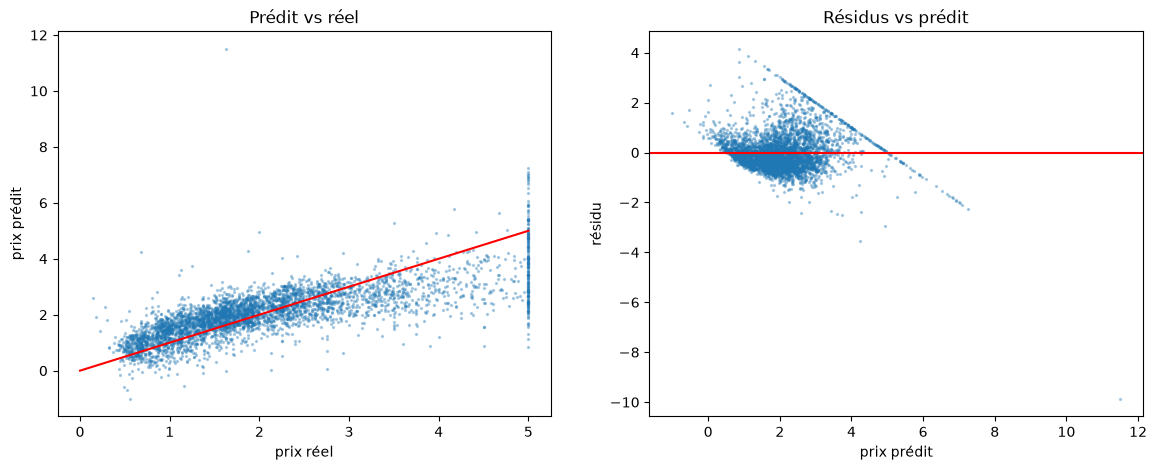

prédictions négatives : 15 | prédictions > 5 : 39


In [10]:
# TODO : graphiques de diagnostic
y_pred_lin = lin.predict(X_test)
residus = y_test - y_pred_lin

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, y_pred_lin, s=2, alpha=0.3)
axes[0].plot([0, 5], [0, 5], color="red")
axes[0].set(xlabel="prix réel", ylabel="prix prédit", title="Prédit vs réel")
axes[1].scatter(y_pred_lin, residus, s=2, alpha=0.3)
axes[1].axhline(0, color="red")
axes[1].set(xlabel="prix prédit", ylabel="résidu", title="Résidus vs prédit")
plt.show()
print("prédictions négatives :", (y_pred_lin < 0).sum(), "| prédictions > 5 :", (y_pred_lin > 5).sum())

✅ **Éléments de réponse**

- Avec toutes les variables, le R² passe de 0,46 à 0,58 et la MAE de 63 à 53 k$ : c'est mieux, mais les graphiques montrent que le modèle reste imparfait.
- **Plafond** : sur le graphique (a), une colonne verticale de points à 5 (prix réels plafonnés), et sur (b) une ligne diagonale de résidus : pour ces quartiers, le modèle ne peut que sous-estimer.
- **Prédictions impossibles** : 15 prix prédits négatifs, et 39 prédictions au-delà du plafond de 5 (jusqu'à 11,5) ; un modèle linéaire n'a pas de bornes.
- **Non-linéarité et variance non constante** : les résidus ne forment pas un nuage homogène, leur dispersion augmente avec le prix prédit (forme d'entonnoir). La relation entre localisation et prix, en particulier, n'est pas linéaire.
- Quelques **points aberrants** isolés (prédictions très éloignées), dus aux quartiers aux valeurs extrêmes de `AveRooms` ou `AveOccup`.

## Partie 4 — Variables polynomiales et régularisation

**4.1** Ajoutez des variables polynomiales de degré 2 (`PolynomialFeatures(degree=2, include_bias=False)`) avant la standardisation. Combien de variables obtient-on ? Évaluez sur le test. Recommencez avec le degré 3. Que se passe-t-il ?

In [11]:
# TODO : régression polynomiale
for degre in [2, 3]:
    poly = make_pipeline(PolynomialFeatures(degree=degre, include_bias=False), StandardScaler(), LinearRegression())
    poly.fit(X_train, y_train)
    n_var = poly[0].n_output_features_
    print(f"degré {degre} : {n_var} variables | R² train = {poly.score(X_train, y_train):.3f}")
    tableau = evaluer(f"polynôme degré {degre}", poly)
tableau

degré 2 : 44 variables | R² train = 0.685


degré 3 : 164 variables | R² train = 0.744


,MAE (k$),RMSE (k$),R²
moyenne,90.607,114.486,-0.000
linéaire (MedInc seul),62.991,84.209,0.459
linéaire (toutes),53.320,74.558,0.576
polynôme degré 2,46.700,68.140,0.646
polynôme degré 3,53.147,498.044,-17.929


✅ **Éléments de réponse**

- Degré 2 : 44 variables. Degré 3 : 164 variables.
- Le degré 2 améliore nettement le modèle linéaire (R² test 0,65 contre 0,58) : les interactions, notamment entre latitude et longitude, capturent une partie de la géographie.
- Le degré 3 s'effondre : R² d'entraînement plus élevé (0,74) mais **R² de test de −18** et RMSE de 500 k$ ! Quelques quartiers extrêmes du test (`AveOccup`, `AveRooms`), élevés au cube et combinés entre eux, produisent des prédictions délirantes. C'est du **sur-apprentissage** aggravé par les valeurs extrêmes : les coefficients non contraints deviennent énormes. La MAE, elle, reste modérée (53 k$) : seules quelques prédictions explosent, et la RMSE les pénalise fortement.

**4.2** Régularisez le modèle de degré 3 avec une régression **Ridge** dont le paramètre `α` est choisi par validation croisée : `RidgeCV(alphas=np.logspace(-2, 4, 25))`. Quel `α` est retenu ? Évaluez.

In [12]:
# TODO : Ridge
ridge = make_pipeline(PolynomialFeatures(degree=3, include_bias=False), StandardScaler(),
                      RidgeCV(alphas=np.logspace(-2, 4, 25)))
ridge.fit(X_train, y_train)
print("alpha retenu :", round(ridge[-1].alpha_, 3))
evaluer("polynôme 3 + Ridge", ridge)

alpha retenu : 3162.278


,MAE (k$),RMSE (k$),R²
moyenne,90.607,114.486,-0.000
linéaire (MedInc seul),62.991,84.209,0.459
linéaire (toutes),53.320,74.558,0.576
polynôme degré 2,46.700,68.140,0.646
polynôme degré 3,53.147,498.044,-17.929
polynôme 3 + Ridge,52.503,72.510,0.599


✅ **Éléments de réponse**

- Ridge retient α ≈ 3 000, une régularisation forte, et **sauve** le modèle de degré 3 : le R² de test remonte de −18 à 0,60, mieux que la régression linéaire simple.
- Il ne bat pourtant pas le simple polynôme de degré 2 (R² 0,65) : la régularisation évite la catastrophe, mais un modèle plus riche n'est utile que s'il capture une vraie structure. Surtout, un modèle linéaire, même enrichi, peine à décrire une carte des prix très irrégulière.

## Partie 5 — Modèles à base d'arbres

**5.1** Entraînez une forêt aléatoire (`RandomForestRegressor(n_estimators=200, min_samples_leaf=2, n_jobs=-1)`) et un `XGBRegressor(n_estimators=1000, learning_rate=0.05, max_depth=7, subsample=0.8, colsample_bytree=0.8)`. Aucune standardisation n'est nécessaire. Évaluez-les.

In [13]:
# TODO : forêt aléatoire et XGBoost
rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)
evaluer("forêt aléatoire", rf)

xgbr = XGBRegressor(n_estimators=1000, learning_rate=0.05, max_depth=7, subsample=0.8,
                    colsample_bytree=0.8, random_state=RANDOM_STATE)
xgbr.fit(X_train, y_train)
evaluer("xgboost", xgbr)

,MAE (k$),RMSE (k$),R²
moyenne,90.607,114.486,-0.000
linéaire (MedInc seul),62.991,84.209,0.459
linéaire (toutes),53.320,74.558,0.576
polynôme degré 2,46.700,68.140,0.646
polynôme degré 3,53.147,498.044,-17.929
polynôme 3 + Ridge,52.503,72.510,0.599
forêt aléatoire,32.605,50.401,0.806
xgboost,28.320,43.551,0.855


**5.2** Tracez l'importance des variables de la forêt aléatoire et du modèle XGBoost côte à côte. Pourquoi la latitude et la longitude sont-elles bien mieux exploitées ici que par la régression linéaire ?

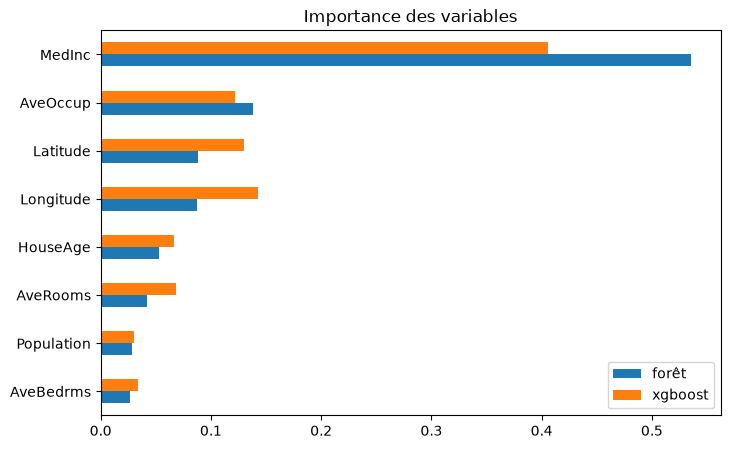

In [14]:
# TODO : importances
importances = pd.DataFrame({"forêt": rf.feature_importances_, "xgboost": xgbr.feature_importances_},
                           index=X.columns)
importances.sort_values("forêt").plot.barh(figsize=(8, 5))
plt.title("Importance des variables")
plt.show()

✅ **Éléments de réponse**

- Les deux ensembles d'arbres réduisent l'erreur de façon spectaculaire par rapport aux modèles linéaires (R² ≈ 0,81 pour la forêt, ≈ 0,86 pour XGBoost, MAE de 33 et 28 k$) : XGBoost est le meilleur.
- `MedInc` reste la variable principale, mais `Latitude`, `Longitude` et `AveOccup` prennent beaucoup d'importance. Un arbre découpe l'espace en **rectangles** (`Latitude < 37,5` et `Longitude < −122`…) : en empilant des centaines de coupures, il dessine une **carte des prix** arbitrairement complexe, là où un modèle linéaire ne peut représenter qu'un « plan incliné ».

**5.3** Vérifiez la limite d'extrapolation des arbres : quelle est la valeur maximale prédite par XGBoost sur le test ? Et par la régression linéaire ? Construisez ensuite un quartier fictif avec un revenu médian de 25 (250 000 $, au-delà du maximum observé), les autres variables égales à la médiane : que prédisent la forêt aléatoire et la régression linéaire ?

In [15]:
# TODO : extrapolation
print("max prédit xgboost :", round(float(xgbr.predict(X_test).max()), 2))
print("max prédit linéaire :", round(float(lin.predict(X_test).max()), 2))

fictif = X_train.median().to_frame().T
for revenu in [5, 10, 15, 25]:
    fictif["MedInc"] = revenu
    print(f"MedInc={revenu:>2} → forêt : {rf.predict(fictif)[0]:.2f} | linéaire : {lin.predict(fictif)[0]:.2f}")

max prédit xgboost : 5.5
max prédit linéaire : 11.5
MedInc= 5 → forêt : 2.47 | linéaire : 2.68
MedInc=10 → forêt : 4.87 | linéaire : 4.93
MedInc=15 → forêt : 4.87 | linéaire : 7.17
MedInc=25 → forêt : 4.87 | linéaire : 11.66


✅ **Éléments de réponse**

- Les prédictions de XGBoost restent proches de l'intervalle des prix observés (maximum 5,5 : le boosting additionne des corrections et peut légèrement déborder), alors que la régression linéaire monte jusqu'à 11,5.
- Pour le quartier fictif, la prédiction de la forêt **plafonne à 4,87** dès que le revenu atteint 10 : au-delà, le quartier tombe toujours dans les mêmes feuilles, et la forêt ne peut prédire qu'une moyenne de prix déjà observés. La régression linéaire, elle, continue de croître (11,7 pour un revenu de 25). Ici le comportement des arbres est plutôt une qualité (les prix sont plafonnés dans les données), mais c'est une limite importante pour des données en croissance (séries temporelles avec tendance, par exemple : voir TP5).

## Partie 6 — Comparaison finale et analyse des erreurs

**6.1** Affichez le tableau `resultats` trié par RMSE.

In [16]:
# TODO : tableau récapitulatif
pd.DataFrame(resultats).T.sort_values("RMSE (k$)").round(3)

,MAE (k$),RMSE (k$),R²
xgboost,28.320,43.551,0.855
forêt aléatoire,32.605,50.401,0.806
polynôme degré 2,46.700,68.140,0.646
polynôme 3 + Ridge,52.503,72.510,0.599
linéaire (toutes),53.320,74.558,0.576
linéaire (MedInc seul),62.991,84.209,0.459
moyenne,90.607,114.486,-0.000
polynôme degré 3,53.147,498.044,-17.929


**6.2** Pour le meilleur modèle, calculez l'erreur absolue moyenne par **tranche de prix réel** (`pd.cut` de `y_test` en tranches de 0 à 1, 1 à 2, … 4 à 5 et « plafond » pour les valeurs ≥ 5). Où le modèle se trompe-t-il le plus ?

In [17]:
# TODO : erreurs par tranche de prix
erreurs = pd.DataFrame({"reel": y_test, "predit": xgbr.predict(X_test)})
erreurs["erreur_abs_k$"] = (erreurs["reel"] - erreurs["predit"]).abs() * 100
erreurs["tranche"] = pd.cut(erreurs["reel"], bins=[0, 1, 2, 3, 4, 4.99, 5.1],
                            labels=["<100k", "100-200k", "200-300k", "300-400k", "400-500k", "plafond"])
erreurs.groupby("tranche", observed=True)["erreur_abs_k$"].agg(["mean", "size"]).round(1)

,mean,size
tranche,,
<100k,19.6,739
100-200k,20.7,1682
200-300k,30.6,956
300-400k,44.0,412
400-500k,61.1,155
plafond,58.8,184


**6.3** Rédigez une courte conclusion pour l'agence immobilière : modèle recommandé, précision attendue, limites.

✅ **Éléments de réponse**

- **Modèle recommandé : XGBoost**, qui explique environ 85 % de la variance des prix et se trompe en moyenne de 28 000 $ (MAE), contre 53 000 $ pour la régression linéaire.
- L'erreur est d'environ 20 k$ pour les quartiers à moins de 200 k$, mais elle augmente fortement avec le prix : 44 k$ entre 300 et 400 k$, environ 60 k$ au-delà de 400 k$ et pour les quartiers **au plafond**, dont le vrai prix est de toute façon inconnu. L'outil est fiable pour le cœur du marché, pas pour le haut de gamme.
- Limites : données de **1990** (les prix ont été multipliés depuis) ; données **agrégées** par quartier et non par logement ; aucune information sur l'état ou la surface du bien. Il s'agit d'un outil d'estimation de marché, pas d'un prix de vente.

## Partie 7 — *Facultatif* : approfondissements

*À faire si vous avez terminé le reste. Les questions sont indépendantes les unes des autres.*

**7.1** Affichez les coefficients du modèle `lin` (variables standardisées) sous forme de diagramme en barres. Quelles variables comptent le plus ? Le signe de `AveRooms` vous surprend-il ? Comment l'expliquer ?

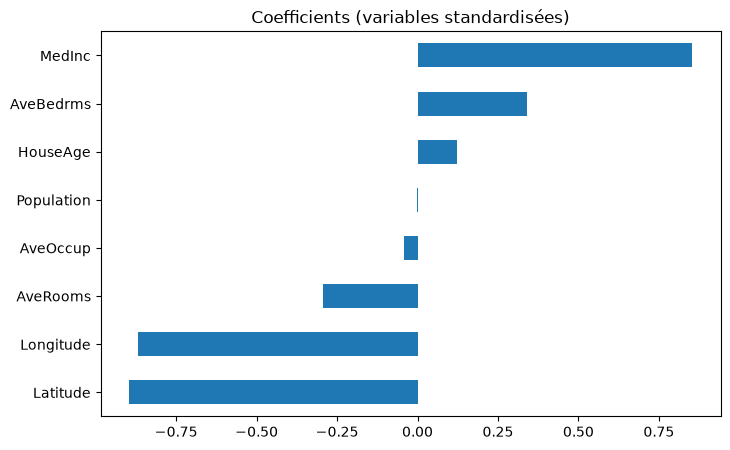

Latitude     -0.897
Longitude    -0.870
AveRooms     -0.294
AveOccup     -0.041
Population   -0.002
HouseAge      0.123
AveBedrms     0.339
MedInc        0.854
dtype: float64
corrélation AveRooms / AveBedrms : 0.85


In [18]:
# TODO : coefficients
coefs = pd.Series(lin[-1].coef_, index=X.columns).sort_values()
coefs.plot.barh()
plt.title("Coefficients (variables standardisées)")
plt.show()
print(coefs.round(3))
print("corrélation AveRooms / AveBedrms :", round(df["AveRooms"].corr(df["AveBedrms"]), 2))

✅ **Éléments de réponse**

- `MedInc` a le plus fort effet positif. `Latitude` et `Longitude` ont de forts coefficients **négatifs** : à revenu égal, aller vers le nord ou vers l'est (vers l'intérieur des terres) fait baisser les prix.
- `AveRooms` a un coefficient **négatif** alors que, seul, le nombre de pièces est plutôt associé à des prix plus élevés. C'est un effet de la **colinéarité** avec `AveBedrms` (corrélation ≈ 0,85) : à nombre de chambres **fixé**, plus de pièces… et le coefficient de `AveBedrms`, lui, est positif. Les deux coefficients se compensent ; il ne faut pas les interpréter isolément (vous avez rencontré le même piège au TP2).

**7.2** Évaluez `lin` par validation croisée à 5 plis (`KFold` avec `shuffle=True`) sur le jeu d'entraînement : RMSE moyen et écart-type. Le résultat est-il stable d'un pli à l'autre ?

In [19]:
# TODO : validation croisée
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rmse_cv = -cross_val_score(lin, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
print("RMSE par pli (k$) :", (rmse_cv * 100).round(1))
print(f"moyenne : {rmse_cv.mean() * 100:.1f} k$ ± {rmse_cv.std() * 100:.1f}")

RMSE par pli (k$) : [73.4 72.5 69.7 73.3 71.3]
moyenne : 72.1 k$ ± 1.4


✅ **Éléments de réponse**

Le RMSE est stable d'un pli à l'autre (72 k$ ± 1,4) et cohérent avec celui mesuré sur le test (75 k$) : la performance de la régression linéaire est estimée de façon fiable. Le modèle est **stable** mais **biaisé** : il est trop simple pour la structure des données (sous-apprentissage).

**7.3** Régularisez le modèle polynomial de degré 3 avec un **Lasso** au lieu d'un Ridge (`LassoCV(cv=5, max_iter=5000, n_jobs=-1)`). Combien de coefficients sont exactement nuls ? Affichez les 10 variables polynomiales de plus fort coefficient (en valeur absolue).

*Le Lasso est plus long à entraîner (une trentaine de secondes).*

In [20]:
# TODO : Lasso
import warnings
from sklearn.exceptions import ConvergenceWarning
# On masque les avertissements de convergence du Lasso pour les très petites valeurs de α
warnings.filterwarnings("ignore", category=ConvergenceWarning)

lasso = make_pipeline(PolynomialFeatures(degree=3, include_bias=False), StandardScaler(),
                      LassoCV(cv=5, max_iter=5000, n_jobs=-1, random_state=RANDOM_STATE))
lasso.fit(X_train, y_train)
coefs_lasso = pd.Series(lasso[-1].coef_, index=lasso[0].get_feature_names_out(X.columns))
print("alpha retenu :", round(lasso[-1].alpha_, 5))
print(f"coefficients nuls : {(coefs_lasso == 0).sum()} / {len(coefs_lasso)}")
print(coefs_lasso.abs().sort_values(ascending=False).head(10).round(3))
evaluer("polynôme 3 + Lasso", lasso)

alpha retenu : 0.00491
coefficients nuls : 137 / 164
Latitude                        0.754
Longitude                       0.721
MedInc^2                        0.586
MedInc^3                        0.448
MedInc HouseAge AveBedrms       0.438
AveOccup                        0.335
MedInc Longitude^2              0.244
AveRooms AveOccup^2             0.238
HouseAge AveRooms Latitude      0.229
HouseAge AveRooms Population    0.211
dtype: float64


,MAE (k$),RMSE (k$),R²
moyenne,90.607,114.486,-0.000
linéaire (MedInc seul),62.991,84.209,0.459
linéaire (toutes),53.320,74.558,0.576
polynôme degré 2,46.700,68.140,0.646
polynôme degré 3,53.147,498.044,-17.929
polynôme 3 + Ridge,52.503,72.510,0.599
forêt aléatoire,32.605,50.401,0.806
xgboost,28.320,43.551,0.855
polynôme 3 + Lasso,50.653,70.979,0.616


✅ **Éléments de réponse**

Lasso met 137 des 164 coefficients **exactement à zéro** : il réalise une **sélection de variables** automatique et produit un modèle plus simple (27 termes), légèrement meilleur que Ridge (R² 0,62 contre 0,60). Les termes conservés font surtout intervenir `Latitude`, `Longitude` et des puissances de `MedInc`. Il ne bat pas non plus le polynôme de degré 2 (R² 0,65).

## Pour aller plus loin (bonus)

- Entraînez la régression linéaire sur `log(MedHouseVal)` grâce à `TransformedTargetRegressor(regressor=..., func=np.log, inverse_func=np.exp)` : les résidus sont-ils plus homogènes ?
- Ajoutez une variable « distance au centre de San Francisco » et « distance au centre de Los Angeles » (coordonnées approximatives : (37,77 ; −122,42) et (34,05 ; −118,24)). La régression linéaire en profite-t-elle ?
- Excluez les quartiers au plafond de l'entraînement : l'erreur sur les autres quartiers diminue-t-elle ?

In [21]:
# Bonus : distances aux grandes villes pour la régression linéaire
def ajouter_distances(X):
    X = X.copy()
    X["dist_SF"] = np.hypot(X["Latitude"] - 37.77, X["Longitude"] + 122.42)
    X["dist_LA"] = np.hypot(X["Latitude"] - 34.05, X["Longitude"] + 118.24)
    return X

lin_dist = make_pipeline(StandardScaler(), LinearRegression())
lin_dist.fit(ajouter_distances(X_train), y_train)
evaluer("linéaire + distances", lin_dist, ajouter_distances(X_test))

,MAE (k$),RMSE (k$),R²
moyenne,90.607,114.486,-0.000
linéaire (MedInc seul),62.991,84.209,0.459
linéaire (toutes),53.320,74.558,0.576
polynôme degré 2,46.700,68.140,0.646
polynôme degré 3,53.147,498.044,-17.929
polynôme 3 + Ridge,52.503,72.510,0.599
forêt aléatoire,32.605,50.401,0.806
xgboost,28.320,43.551,0.855
polynôme 3 + Lasso,50.653,70.979,0.616
linéaire + distances,53.353,74.451,0.577
